In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

batch_log = pd.read_csv("../data/raw/batch_log.csv", parse_dates=["StartTimestamp"])
process_parameters = pd.read_csv("../data/raw/process_parameters.csv")
quality_table = pd.read_csv("../data/raw/quality_table.csv")


### Shape and Percent OOS

In [2]:
shape=batch_log.shape, process_parameters.shape, quality_table.shape
oos_flags_percent = round(quality_table['OOS_Flag'].mean(),2)

for j, a in shape:
    print(f"Columns: {a} Rows: {j}")


print(f"{oos_flags_percent*100}% of batches are marked OOS (Out-Of_Specification)")


Columns: 5 Rows: 3000
Columns: 4 Rows: 27000
Columns: 6 Rows: 3000
22.0% of batches are marked OOS (Out-Of_Specification)


In [3]:
merged_all= pd.pivot_table(process_parameters, values="Param_Value", columns="Param_Name", index="Batch_ID").merge(batch_log, on="Batch_ID").merge(quality_table, on="Batch_ID")

In [4]:
merged_all

,Batch_ID,Blender_load_%,Coating_Spray_Rate,Coating_Time_Min,Granulation_Moisture_%,Granulation_Temp_C,Granulation_Time_Min,Inlet_Temp_C,Mixing_Speed_RPM,Mixing_Time_Min,Product_ID,Line_ID,Operator,StartTimestamp,Assay,Dissolution,Impurity,Hardness,OOS_Flag
0,BATCH_0001,64.1951,7.7535,32.0761,2.4827,62.5640,20.5537,59.3939,124.9493,12.5048,CardioStat_IR,Line_2,Operator_A,2023-01-01 06:00:00,96.145266,90.0,0.200000,7,1
1,BATCH_0002,70.0006,7.6885,32.9209,2.8915,63.7867,18.9745,56.7596,122.4041,13.8348,CardioStat_IR,Line_2,Operator_B,2023-01-01 16:00:00,95.873683,90.0,0.200000,7,1
2,BATCH_0003,56.6179,10.4212,38.8662,3.8597,68.1738,22.3567,58.4942,175.9589,17.2952,CardioStat_IR,Line_2,Operator_B,2023-01-02 00:00:00,100.000000,90.0,0.200000,7,0
3,BATCH_0004,60.5145,8.0295,31.1342,2.7301,57.3226,24.3476,53.6096,160.6256,11.3101,NeuroCalm_IR,Line_2,Operator_D,2023-01-02 10:00:00,100.000000,90.0,0.200000,7,0
4,BATCH_0005,69.7215,8.4464,36.7114,2.6197,70.1598,14.1825,48.8420,140.1366,14.3277,NeuroCalm_IR,Line_1,Operator_A,2023-01-02 20:00:00,100.000000,90.0,0.508155,7,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,BATCH_2996,64.2908,6.9663,29.3519,2.1360,61.2951,29.0460,46.3982,144.6094,16.0971,GastroEase_CR,Line_2,Operator_D,2026-01-25 03:00:00,100.000000,90.0,0.200000,7,0
2996,BATCH_2997,65.1828,9.5451,24.9349,2.6168,59.8313,20.7728,48.5186,136.2273,13.4538,GastroEase_CR,Line_1,Operator_A,2026-01-25 13:00:00,100.000000,90.0,0.200000,7,0
2997,BATCH_2998,67.1262,7.2713,26.0878,2.8179,60.3138,13.5630,46.6020,158.9730,14.0584,CardioStat_IR,Line_1,Operator_C,2026-01-25 21:00:00,100.000000,90.0,0.200000,7,0
2998,BATCH_2999,89.7713,5.9213,36.8964,2.4622,57.5501,16.7844,53.6137,131.6010,11.9332,NeuroCalm_IR,Line_2,Operator_C,2026-01-26 05:00:00,100.000000,90.0,0.200000,7,0


### EDA

### Q1. Product-wise OOS Performance. How does each product perform in terms of OOS rate?

In [5]:
merged_all.groupby("Product_ID")["OOS_Flag"].mean()

Product_ID
CardioStat_IR    0.197927
GastroEase_CR    0.039370
NeuroCalm_IR     0.407262
Name: OOS_Flag, dtype: float64

### Observed Results:

NeuroCalm_IR: 40.7% OOS (highest)

CardioStat_IR: 19.8% OOS

GastroEase_CR: 3.9% OOS (lowest)

---

### Interpretation:
NeuroCalm_IR shows a significantly higher failure rate, indicating that granulation-related parameters are currently the most sensitive and failure-prone in the simulated process. CardioStat_IR exhibits moderate OOS driven by mixing variability, while GastroEase_CR appears comparatively stable, suggesting that coating-related failures are less frequent under current operating ranges.

---

### Business Insight:
Quality improvement efforts should prioritize NeuroCalm_IR granulation controls, followed by CardioStat_IR mixing optimization. GastroEase_CR may require monitoring rather than aggressive intervention.

---

### Q2. OOS Trend Over Time (Rolling Average). Is there time-based drift, leakage, or instability?

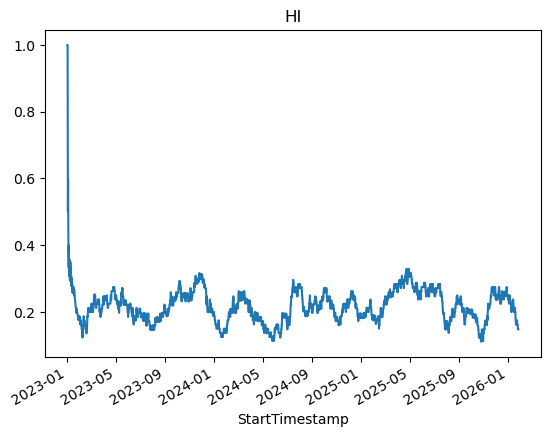

In [6]:
merged_all.set_index("StartTimestamp")["OOS_Flag"].rolling("30D").mean().plot(title="HI")
plt.show()

### Observed Results:

Rolling 30-day OOS rate fluctuates within a stable band

No sustained upward or downward trend

Early spike is attributable to rolling window edge effects

---

### Interpretation:
The process is time-stationary. OOS occurrences are driven by process conditions rather than calendar time, and there is no evidence of data leakage or artificial drift.

---

### Business Insight:
This confirms that predictive models can safely use historical data without needing time-based correction factors.

---

### Q3. Single-Parameter Level EDA. How does OOS behavior change with individual parameters?

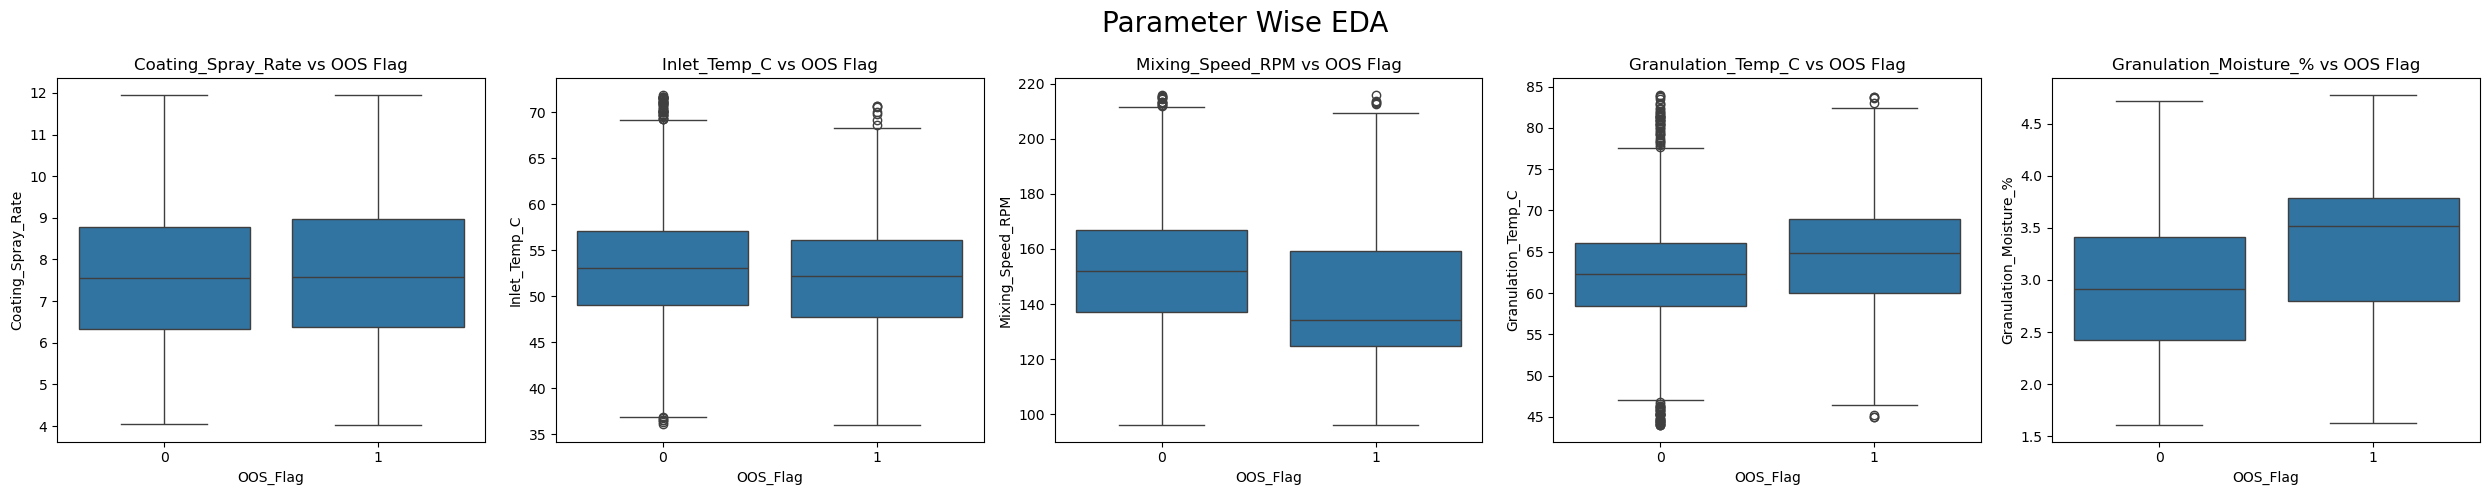

In [7]:
params= ["Coating_Spray_Rate", "Inlet_Temp_C", "Mixing_Speed_RPM", "Granulation_Temp_C", "Granulation_Moisture_%"]

fig, axes = plt.subplots(1, 5, figsize=(25, 5))
for ind, param in enumerate(params):
    sns.boxplot(data=merged_all, x="OOS_Flag", y=param, ax=axes[ind])
    axes[ind].set_title(f"{param} vs OOS Flag")
fig.suptitle("Parameter Wise EDA", fontsize=20)
plt.tight_layout()
plt.show()

### Observed Patterns:

OOS batches show shifted distributions and wider spread for critical parameters
Supporting parameters alone do not cause failures

---

Key drivers:
Low Mixing_Speed_RPM
High Granulation_Temp_C
High Granulation_Moisture_%
High Coating_Spray_Rate

---

### Interpretation:
Failures are not random; they emerge when critical parameters drift toward risky regions. Variability, not just mean shift, is a strong indicator of failure risk.

---

### Business Insight:
Single parameters can act as early warning indicators, but should not be used in isolation for decision-making.

---

### Q4. Product-Wise Sensitive Parameter Analysis. Do different products fail for different reasons?

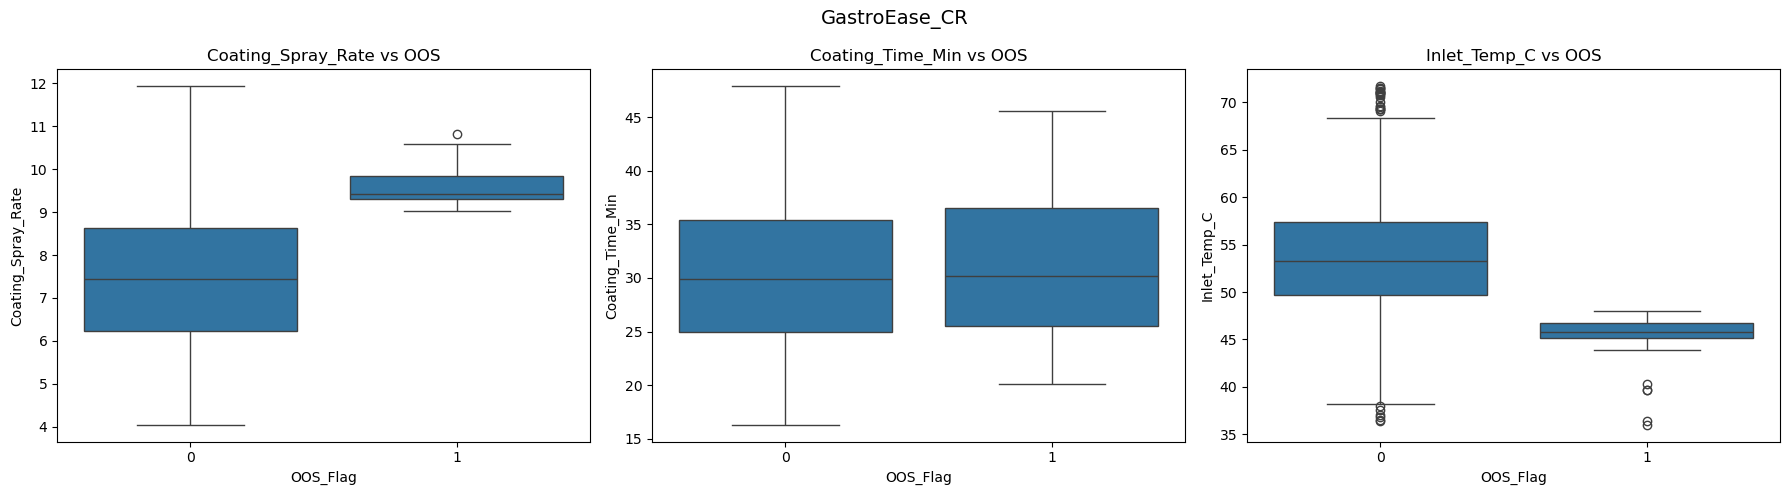

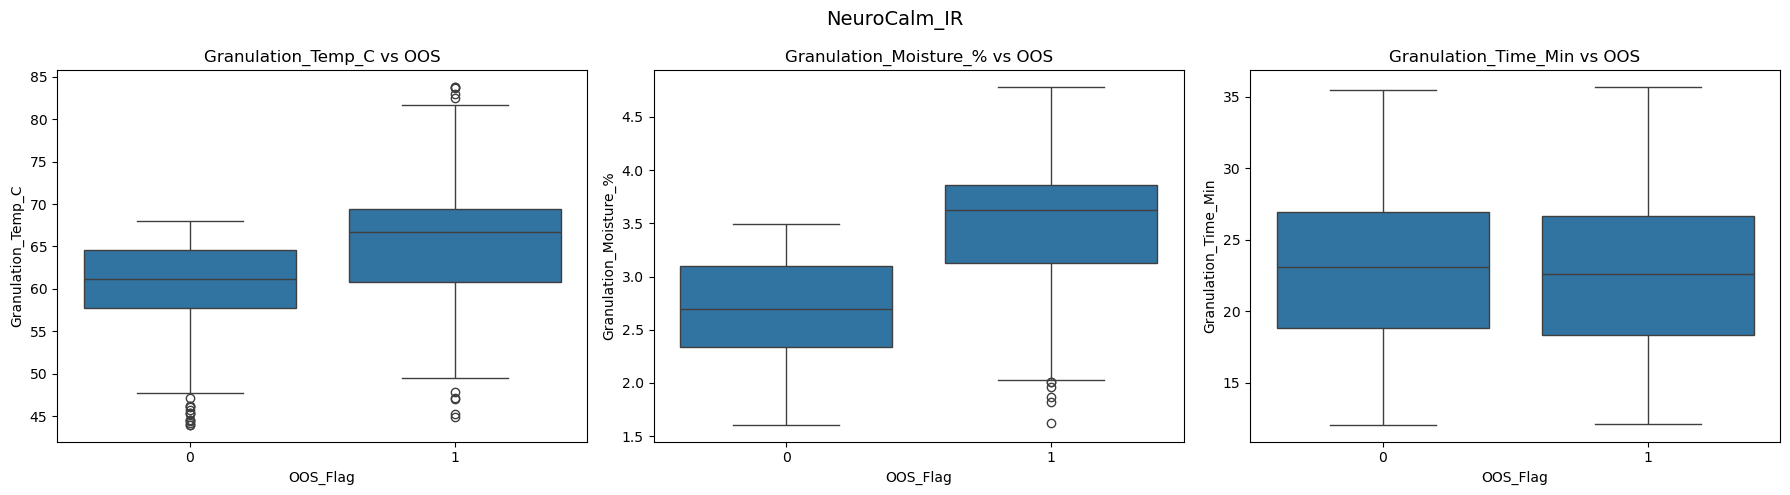

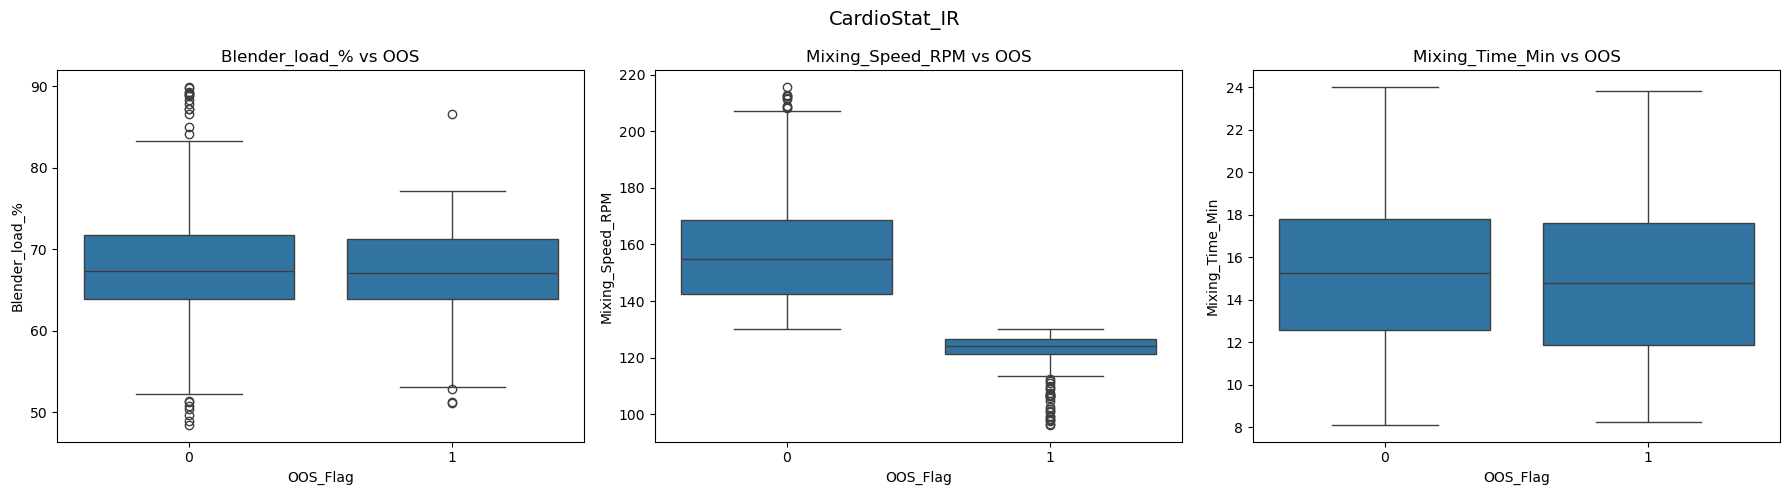

In [8]:
product_params = {
    "GastroEase_CR": ['Coating_Spray_Rate','Coating_Time_Min','Inlet_Temp_C'],
    "NeuroCalm_IR": ['Granulation_Temp_C','Granulation_Moisture_%','Granulation_Time_Min'],
    "CardioStat_IR": ['Blender_load_%', 'Mixing_Speed_RPM', 'Mixing_Time_Min']
}

for product, params in product_params.items():
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    for idx, param in enumerate(params):
        sns.boxplot(
            data=merged_all.query(f"Product_ID == '{product}'"),
            x="OOS_Flag",
            y=param,
            ax=axes[idx]
        )
        axes[idx].set_title(f"{param} vs OOS")
    
    fig.suptitle(f"{product}", fontsize=14)
    plt.tight_layout()
    plt.show()


### Observed Results:

CardioStat_IR: Strong sensitivity to Mixing_Speed_RPM

NeuroCalm_IR: High sensitivity to Granulation_Temp_C and Moisture

GastroEase_CR: Sensitivity to Coating_Spray_Rate and Inlet_Temp_C

---

### Interpretation:
Each product exhibits distinct failure mechanics, confirming that a single global control strategy would be ineffective.

---

### Business Insight:
Control limits and monitoring strategies must be product-specific, aligned with the dominant manufacturing step.

---

### Q5. Interaction (Two-Parameter) EDA. Do combinations of parameters amplify OOS risk?

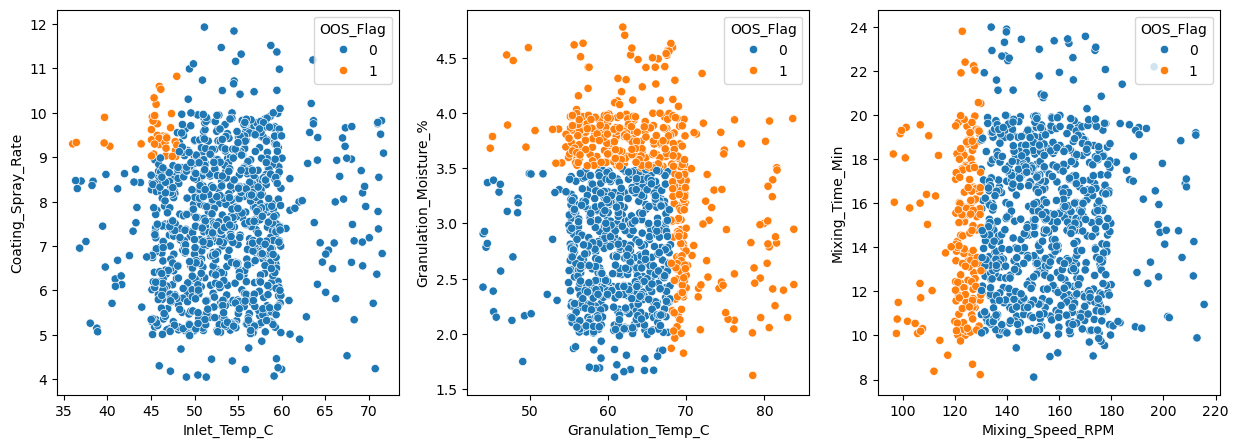

In [9]:
Interact_param={
    "GastroEase_CR": ["Coating_Spray_Rate","Inlet_Temp_C"],
    "NeuroCalm_IR": ["Granulation_Moisture_%","Granulation_Temp_C"],
    "CardioStat_IR": ["Mixing_Time_Min","Mixing_Speed_RPM"]
}
fig, axes = plt.subplots(1, 3, figsize=(15,5))
for ind, (prod, param) in enumerate(Interact_param.items()):
    sns.scatterplot(data=merged_all.query(f"Product_ID=='{prod}'"),y=param[0], x=param[1], hue="OOS_Flag", ax=axes[ind])


### Observed Results:

OOS clusters appear when two adverse conditions co-occur

Safe operating zones exist where one parameter compensates for another

Risk behavior is non-linear

---

### Interpretation:
Most failures arise from parameter interactions, not isolated deviations. Remaining “in-spec” on individual parameters does not guarantee batch success.

---

### Business Insight:
Operational monitoring should focus on parameter combinations, not siloed limits.

---

### Q6. Variability (Standard Deviation) Analysis. Are OOS batches more unstable?

In [10]:
merged_all.groupby("OOS_Flag")[params].std()

,Blender_load_%,Mixing_Speed_RPM,Mixing_Time_Min
OOS_Flag,,,
0,6.317745,20.072068,3.236104
1,5.873357,22.718387,3.282189


### Observed Results (Std Dev):

OOS batches show higher variability across all critical parameters

Example:

Mixing Speed: OOS > Non-OOS

Granulation Temp & Moisture: OOS > Non-OOS

---

### Interpretation:
Loss of process stability is a key driver of failures, often more important than absolute setpoints.

---

### Business Insight:
Reducing variability may reduce OOS without changing target values, a classic CI lever.

---

### Q7. Correlation Analysis. How are parameters related to each other?

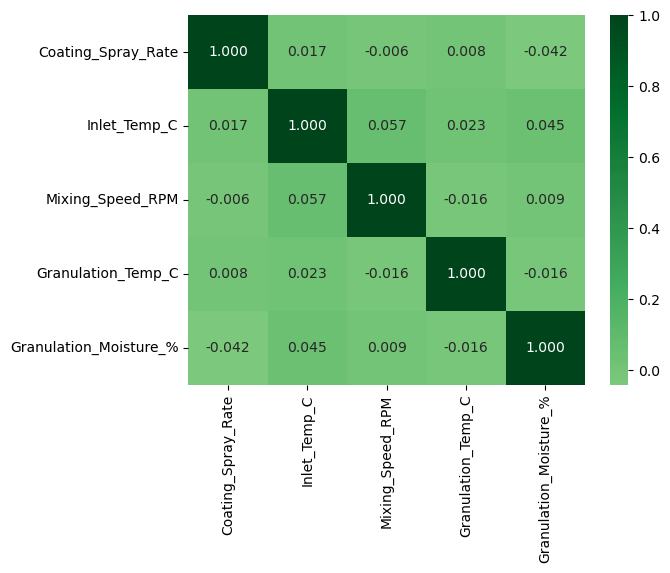

In [11]:
params= ["Coating_Spray_Rate", "Inlet_Temp_C", "Mixing_Speed_RPM", "Granulation_Temp_C", "Granulation_Moisture_%"]
corr = merged_all[params].corr()
sns.heatmap(corr, cmap="Greens", center=0, annot=True, fmt=".3f")
plt.show()

### Observed Results:

Low to moderate correlations

No severe multicollinearity

Expected intra-step relationships only

---

### Interpretation:
Correlation structure is benign and does not explain failures on its own. Interactions matter more than linear relationships.

---

### Business Insight:
The dataset is well-suited for tree-based ML models and interaction-aware methods.

--- 